# Fitness cost of resistance and treatment duration

Two questions from the project checklist, both asked of `resilience_model.py`:

1. **How does the fitness cost of resistance affect community recovery across antibiotic concentrations?** The carrier (k30) pays `resistance_cost` as a constant fractional loss of its maximum growth rate, with or without drug. The cost is swept from 0 to 0.5 (the model's tested range; the README gives 0–0.15 as realistic for a plasmid-borne β-lactamase) against carbenicillin doses from 10 to 500 µg/ml.
2. **How does the duration of antibiotic treatment influence composition after recovery?** `treatment_h` is the time from drug addition (4 h) to the 1:100 transfer into drug-free medium. The protocol uses 20 h. It is swept from 0.5 to 44 h, with recovery always 24 h after the transfer.

Everything else stays at baseline unless stated: 57 strains drawn with `seed = 42`, one immune, degrading carrier (`n_resistant = 1`), `vmax = 10⁴`, drug added at 4 h.

### Readouts

All readouts are taken **at the end of recovery, 24 h after the transfer**, against a **matched untreated control on the same schedule**. Treated and control cultures then differ only in the drug.

This matters for the duration sweep. The model's built-in `metrics` read at fixed clock times (48 h, and 24 h for some), which are only the end of recovery and the transfer when `treatment_h = 20`. The `readouts()` helper below reads at times set by the schedule instead. At the default schedule it is checked to match `metrics` exactly.

| Readout | Meaning |
|---|---|
| `compositional_resilience` | 1 − Bray–Curtis between treated and untreated communities (1 = composition unchanged) |
| `carrier_share` | the carrier's relative abundance in the treated community (takeover) |
| `protected_composition` | 1 − Bray–Curtis among the **56 non-carriers only**: how much the drug reshuffled the strains it was meant to spare, independent of takeover |
| `protected_richness` | non-carriers above the 10⁻⁴ detection limit (of 56) |
| `protected_extinct` | non-carriers truly gone (below one cell), as opposed to undetected |
| `biomass_resilience` | treated ÷ untreated total biomass |
| `sensitive_richness` | strains detected in the matched **all-sensitive** community (no carrier) after the same treatment |
| `drug_clearance_h` | hours from drug addition until the drug falls below the median susceptible IC50; NaN if the drug is not cleared before the transfer |
| `carrier_od_at_drug` | carrier biomass when the drug is added (4 h) |

In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))          # resilience_model.py lives one level up
from resilience_model import (run, check, BASELINE, snapshot, detected, shannon, richness,
                              bray_curtis)

OUT = Path("cost_and_duration_results")
(OUT / "figures").mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "grid.linewidth": 0.6, "lines.linewidth": 2.0})
# Okabe-Ito, as in the other analysis notebooks (colorblind-safe)
BLUE, ORANGE, GREEN, VERMILION, PURPLE, SKY, GREY = (
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#7F7F7F")

checks = check(verbose=False)
print(f"{int(checks.passed.sum())}/{len(checks)} model sanity checks passed")
assert checks.passed.all(), checks[~checks.passed]


def save(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png", dpi=150, bbox_inches="tight")


def readouts(r):
    # End-of-recovery readouts for any schedule, against the matched untreated control.
    p = r.params
    t_drug = p.pregrowth_h
    t_transfer = p.pregrowth_h + p.treatment_h
    t_end = t_transfer + p.recovery_h
    trt = r.runs[("resistant", True)]
    car = trt["carrier"]; prot = ~car
    raw = snapshot(trt, t_end)
    xt = detected(raw, p)
    xc = detected(snapshot(r.runs[("resistant", False)], t_end), p)
    st = detected(snapshot(r.runs[("sensitive", True)], t_end), p)
    # clearance: first stored point during treatment with drug below the median IC50
    t, a = trt["t"], trt["a"]
    start = int(np.argmax((t >= t_drug - 1e-9) & (a > 0)))
    stop = int(np.argmax(t >= t_transfer - 1e-9))
    below = np.flatnonzero(a[start:stop + 1] < p.susceptible_ic50)
    clearance = (float(t[start + below[0]] - t_drug)
                 if p.dose > p.susceptible_ic50 and below.size else np.nan)
    ratio = lambda x, y: float(x / y) if y > 0 else np.nan
    return pd.Series(dict(
        compositional_resilience=1 - bray_curtis(xt, xc),
        carrier_share=ratio(xt[car].sum(), xt.sum()),
        carrier_share_control=ratio(xc[car].sum(), xc.sum()),
        protected_composition=(1 - bray_curtis(xt[prot], xc[prot])
                               if xt[prot].sum() > 0 else 0.0),
        protected_richness=richness(xt[prot]),
        protected_extinct=int((raw[prot] <= 0).sum()),
        protected_shannon_ratio=ratio(shannon(xt[prot]), shannon(xc[prot])),
        shannon_resilience=ratio(shannon(xt), shannon(xc)),
        biomass_resilience=ratio(xt.sum(), xc.sum()),
        sensitive_richness=richness(st),
        drug_clearance_h=clearance,
        drug_at_transfer=float(a[stop]),
        carrier_od_at_drug=float(snapshot(trt, t_drug)[car].sum()),
    ))


def table(cache, rows_fn, recompute=False):
    # Compute a results table once and reload it afterwards, like sweep(cache=...).
    path = OUT / cache
    if path.exists() and not recompute:
        return pd.read_csv(path)
    df = pd.DataFrame(rows_fn())
    df.to_csv(path, index=False)
    return df


def runs(grid_rows):
    # grid_rows: list of dicts of parameter changes -> one row per run (changes + readouts)
    return [{**ch, **readouts(run(**ch)).to_dict()} for ch in grid_rows]


# readouts() must agree with the model's own metrics at the default schedule
for ch in [{}, dict(dose=70), dict(resistance_cost=0.3, dose=150), dict(carrier_lysis=1.0)]:
    r = run(**ch); a, m = readouts(r), r.metrics
    for k_a, k_m in [("compositional_resilience", "compositional_resilience"),
                     ("carrier_share", "resistant_share"),
                     ("protected_richness", "protected_richness"),
                     ("protected_extinct", "protected_extinct"),
                     ("biomass_resilience", "biomass_resilience"),
                     ("sensitive_richness", "sensitive_richness_treated"),
                     ("drug_clearance_h", "drug_clearance_h")]:
        assert np.isclose(a[k_a], m[k_m], equal_nan=True), (ch, k_a, a[k_a], m[k_m])
print("readouts() matches the model's metrics at the default schedule")

20/20 model sanity checks passed


readouts() matches the model's metrics at the default schedule


In [2]:
def heatmap(ax, df, x, y, z, cmap="viridis", vmin=0, vmax=1, fmt="{:.2f}", ann=True,
            xlabel=None, ylabel=None, title=None):
    piv = df.pivot_table(index=y, columns=x, values=z).sort_index(ascending=False)
    im = ax.imshow(piv.values, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels([f"{v:g}" for v in piv.columns],
                                                           rotation=90, fontsize=7)
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels([f"{v:g}" for v in piv.index],
                                                           fontsize=7)
    ax.grid(False)
    if ann:
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                v = piv.values[i, j]
                if np.isfinite(v):
                    rgb = np.array(im.cmap(im.norm(v))[:3])
                    lum = rgb @ [0.299, 0.587, 0.114]          # label colour from cell colour
                    ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=5.5,
                            color="white" if lum < 0.5 else "black")
    ax.set(xlabel=xlabel or x, ylabel=ylabel or y)
    if title:
        ax.set_title(title, fontsize=9)
    return im

# Part 1. Fitness cost × antibiotic concentration

## 1.1 The full grid

11 costs × 13 doses. A cost changes the carrier's growth with or without drug, so the untreated control changes too. Compositional resilience is always measured against the control with the same cost.

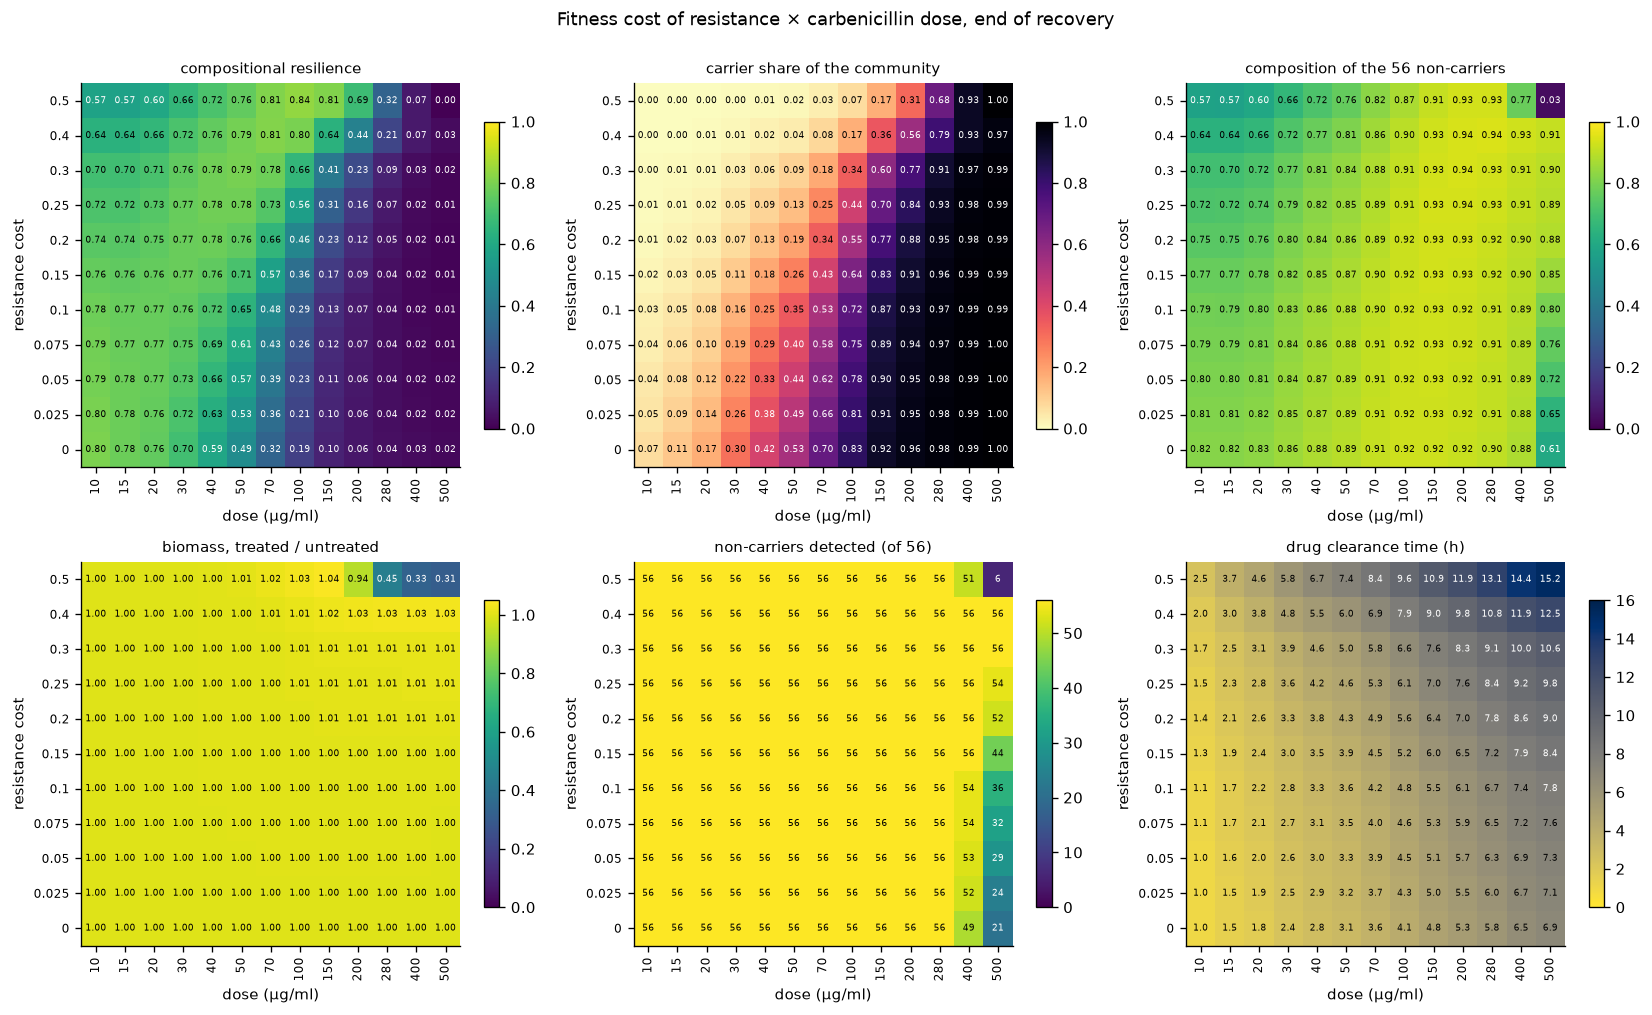

In [3]:
COSTS = [0.0, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
DOSES = [10, 15, 20, 30, 40, 50, 70, 100, 150, 200, 280, 400, 500]
cost_grid = table("01_cost_x_dose.csv", lambda: runs(
    [dict(resistance_cost=c, dose=float(d)) for c in COSTS for d in DOSES]))
cost_grid["full_rescue"] = ((cost_grid.protected_richness == 56) &
                            (cost_grid.biomass_resilience >= 0.9))

fig, axs = plt.subplots(2, 3, figsize=(14, 8.4))
specs = [("compositional_resilience", "compositional resilience", "viridis", 0, 1, "{:.2f}"),
         ("carrier_share", "carrier share of the community", "magma_r", 0, 1, "{:.2f}"),
         ("protected_composition", "composition of the 56 non-carriers", "viridis", 0, 1, "{:.2f}"),
         ("biomass_resilience", "biomass, treated / untreated", "viridis", 0, 1.05, "{:.2f}"),
         ("protected_richness", "non-carriers detected (of 56)", "viridis", 0, 56, "{:.0f}"),
         ("drug_clearance_h", "drug clearance time (h)", "cividis_r", 0, 16, "{:.1f}")]
for ax, (z, title, cmap, lo, hi, fmt) in zip(axs.flat, specs):
    im = heatmap(ax, cost_grid, "dose", "resistance_cost", z, cmap, lo, hi, fmt,
                 xlabel="dose (µg/ml)", ylabel="resistance cost", title=title)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("Fitness cost of resistance × carbenicillin dose, end of recovery", y=1.0)
fig.tight_layout(); save(fig, "01_cost_x_dose_heatmaps"); plt.show()

### What the grid shows

- **Survival hardly depends on the cost, but composition depends on it strongly.** For the immune degrader, no non-carrier goes extinct anywhere on the grid except at cost 0.5 with ≥ 280 µg/ml (see 1.3). Biomass recovers fully everywhere else. Where the cost does matter is in **how much the carrier takes over**, and through that, compositional resilience.
- **Cost works against takeover.** At 50 µg/ml the carrier ends at 53% of the community with no cost, 44% at the baseline 0.05, and 9% at 0.3. Compositional resilience rises from 0.49 to 0.79 over the same range. At 150 µg/ml the rise is from 0.10 to 0.84 (cost 0.4–0.5).
- **Cost slows clearance.** Clearance time rises with both dose and cost: 3.3 h at the baseline, 7.4 h at 50 µg/ml with cost 0.5, and 15 h at 500 µg/ml with cost 0.5.
- **The non-carriers are reshuffled most at *low* doses.** Their own composition (top right) is lowest at 10–20 µg/ml (0.57–0.82) and highest at 100–280 µg/ml (≈ 0.92). Near the IC50s, only the most drug-sensitive strains are killed, which is selective. Well above all the IC50s, every strain is killed at close to the same, maximal rate, which preserves their proportions (see Part 3).
- **High doses and high costs together are where recovery fails.** At cost 0.5 and ≥ 280 µg/ml, the carrier is too slow to clear the drug before the susceptible strains are lost. Biomass resilience drops to 0.3–0.45, and at 500 µg/ml 50 of 56 strains are truly extinct.

## 1.2 Two opposing effects of the cost

Read along the cost axis at fixed doses. The left two panels split compositional resilience into its two parts: how much the carrier takes over, and how much the non-carriers are reshuffled among themselves. The right two panels show the mechanism: a costly carrier has less biomass, and so less enzyme, when the drug arrives, so it clears the drug more slowly.

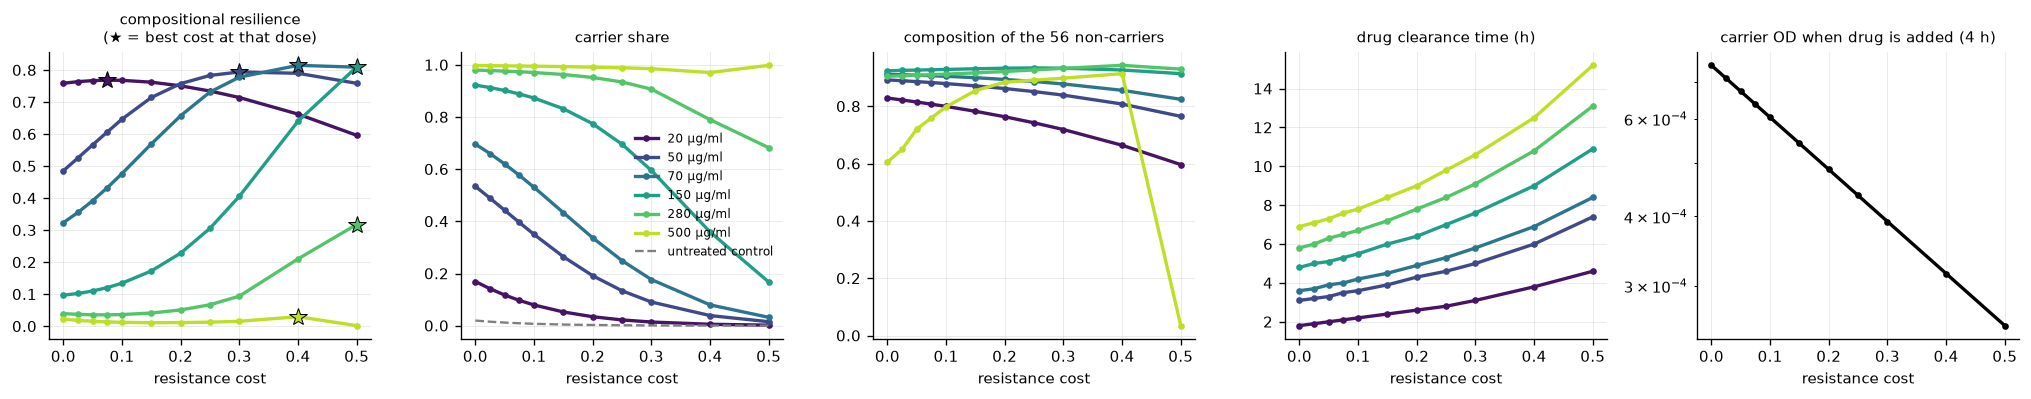

 dose  best_cost  best_resilience  resilience_at_cost_0.05
 10.0      0.000            0.801                    0.792
 15.0      0.025            0.777                    0.776
 20.0      0.075            0.768                    0.767
 30.0      0.200            0.772                    0.735
 40.0      0.250            0.783                    0.663
 50.0      0.300            0.794                    0.567
 70.0      0.400            0.815                    0.392
100.0      0.500            0.837                    0.229
150.0      0.500            0.810                    0.110
200.0      0.500            0.685                    0.064
280.0      0.500            0.318                    0.036
400.0      0.400            0.068                    0.022
500.0      0.400            0.030                    0.016


In [4]:
LINE_DOSES = [20, 50, 70, 150, 280, 500]
dcol = dict(zip(LINE_DOSES, plt.cm.viridis(np.linspace(0.05, 0.9, len(LINE_DOSES)))))
fig, axs = plt.subplots(1, 5, figsize=(17, 3.4))
for d in LINE_DOSES:
    s = cost_grid[cost_grid.dose == d].sort_values("resistance_cost")
    kw = dict(color=dcol[d], marker="o", ms=3, label=f"{d:g} µg/ml")
    axs[0].plot(s.resistance_cost, s.compositional_resilience, **kw)
    best = s.loc[s.compositional_resilience.idxmax()]
    axs[0].plot(best.resistance_cost, best.compositional_resilience, "*", ms=11,
                color=dcol[d], mec="k", mew=0.6)
    axs[1].plot(s.resistance_cost, s.carrier_share, **kw)
    axs[2].plot(s.resistance_cost, s.protected_composition, **kw)
    axs[3].plot(s.resistance_cost, s.drug_clearance_h, **kw)
s = cost_grid[cost_grid.dose == 50].sort_values("resistance_cost")
axs[4].plot(s.resistance_cost, s.carrier_od_at_drug, color="k", marker="o", ms=3)
axs[1].plot(s.resistance_cost, s.carrier_share_control, color=GREY, ls="--", lw=1.4,
            label="untreated control")
for ax, t in zip(axs, ["compositional resilience\n(★ = best cost at that dose)",
                       "carrier share", "composition of the 56 non-carriers",
                       "drug clearance time (h)", "carrier OD when drug is added (4 h)"]):
    ax.set_title(t, fontsize=9); ax.set_xlabel("resistance cost")
axs[4].set_yscale("log")
axs[1].legend(frameon=False, fontsize=7, ncol=1)
fig.tight_layout(); save(fig, "02_cost_two_effects"); plt.show()

best_cost = (cost_grid.loc[cost_grid.groupby("dose").compositional_resilience.idxmax(),
                           ["dose", "resistance_cost", "compositional_resilience"]]
             .rename(columns={"resistance_cost": "best_cost",
                              "compositional_resilience": "best_resilience"}))
at_005 = cost_grid[cost_grid.resistance_cost == 0.05].set_index("dose").compositional_resilience
best_cost["resilience_at_cost_0.05"] = best_cost.dose.map(at_005)
best_cost.to_csv(OUT / "02_best_cost_by_dose.csv", index=False)
print(best_cost.round(3).to_string(index=False))

### Two opposing effects, and an optimal cost that rises with dose

The cost acts through one mechanism, **slower carrier growth**, with two consequences that pull in opposite directions:

1. **Less takeover (good for composition).** A costly carrier grows more slowly both during and after treatment. Its share falls steeply with cost at every dose (second panel). In the untreated control the carrier stays below 2% at any cost, so almost all of the treated share is drug-driven enrichment.
2. **Slower drug removal (bad for the susceptibles).** By the time drug is added at 4 h, a carrier paying 0.5 has about 3× less biomass than a cost-free one (8×10⁻⁴ vs 2.6×10⁻⁴ OD, last panel). This matches exp(0.5 × 0.55 h⁻¹ × 4 h) ≈ 3. Less biomass means less enzyme, so clearance takes longer (fourth panel). The non-carriers then spend longer in drug, and their composition degrades (third panel, most visibly at 10–20 and 500 µg/ml).

Which effect wins depends on dose:

| Dose (µg/ml) | Best cost (★) | Compositional resilience at best cost | ... at the baseline cost 0.05 |
|---|---|---|---|
| 10 | 0 | 0.80 | 0.79 |
| 20 | 0.075 | 0.77 | 0.77 |
| 50 | 0.3 | 0.79 | 0.57 |
| 70 | 0.4 | 0.82 | 0.39 |
| 150 | 0.5 | 0.81 | 0.11 |
| 280 | 0.5 | 0.32 | 0.04 |
| 500 | 0.4 | 0.03 | 0.02 |

- **At low dose** there is little takeover to prevent, so the cost's only effect is to slow clearance. Cost is neutral to harmful.
- **At intermediate dose** (50–200 µg/ml) takeover dominates the loss of composition. A substantial cost (0.3–0.5) improves compositional resilience by 0.2–0.7.
- **At very high dose** neither effect can save composition. A carrier cheap enough to clear the drug quickly takes over; one costly enough not to take over cannot clear it in time.

In short, **the cost of resistance trades rescue speed against takeover, and the higher the dose, the more of that trade-off favors a costly carrier.**

## 1.3 Where rescue fails: the highest dose fully rescued, by cost

Two definitions of rescue, because they come apart:

- **Survived:** no non-carrier goes extinct (falls below one cell), and community biomass is at least 90% of the untreated control.
- **Detected:** additionally, all 56 non-carriers are above the 10⁻⁴ detection limit. A carrier that takes over more than 99.99% of the community can push living strains below detection, so this is the stricter, sequencing-style criterion.

For each cost, the highest qualifying dose is found by bisection on a log scale between 10 and 500 µg/ml. 500 µg/ml is the top of the model's tested range.

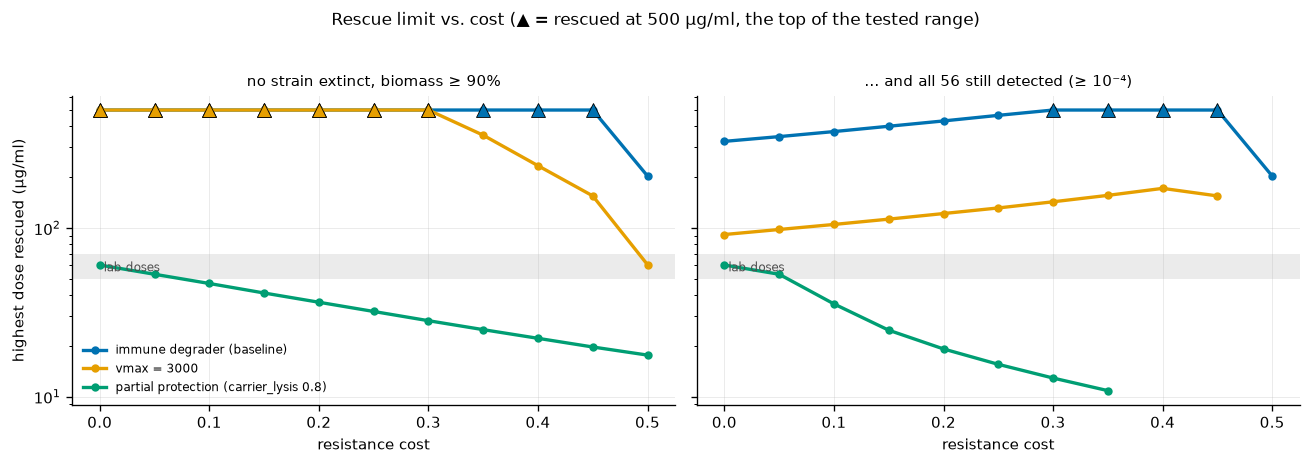

carrier         immune degrader (baseline)          partial protection (carrier_lysis 0.8)          vmax = 3000         
criterion                         detected survived                               detected survived    detected survived
resistance_cost                                                                                                         
0.00                                 326.0    500.0                                   60.0     60.0        91.0    500.0
0.05                                 348.0    500.0                                   53.0     53.0        98.0    500.0
0.10                                 373.0    500.0                                   35.0     47.0       105.0    500.0
0.15                                 401.0    500.0                                   25.0     41.0       113.0    500.0
0.20                                 431.0    500.0                                   19.0     36.0       122.0    500.0
0.25                            

In [5]:
def rescued(cost, dose, criterion, **kw):
    m = readouts(run(resistance_cost=cost, dose=float(dose), **kw))
    ok = m.protected_extinct == 0 and m.biomass_resilience >= 0.9
    if criterion == "detected":
        ok = ok and m.protected_richness == 56
    return bool(ok)


def max_rescued_dose(cost, criterion, lo=10.0, hi=500.0, steps=10, **kw):
    if rescued(cost, hi, criterion, **kw):
        return hi, True                      # rescued at the top of the tested range
    if not rescued(cost, lo, criterion, **kw):
        return np.nan, False
    for _ in range(steps):
        mid = np.sqrt(lo * hi)
        lo, hi = (mid, hi) if rescued(cost, mid, criterion, **kw) else (lo, mid)
    return lo, False


EDGE_COSTS = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]
EDGE_CARRIERS = {"immune degrader (baseline)": {},
                 "vmax = 3000": dict(vmax=3000.0),
                 "partial protection (carrier_lysis 0.8)": dict(carrier_lysis=0.8)}


def edge_rows():
    rows = []
    for name, kw in EDGE_CARRIERS.items():
        for crit in ("survived", "detected"):
            for c in EDGE_COSTS:
                d, capped = max_rescued_dose(c, crit, **kw)
                rows.append(dict(carrier=name, criterion=crit, resistance_cost=c,
                                 max_rescued_dose=d, capped_at_500=capped))
    return rows


edge = table("03_max_rescued_dose.csv", edge_rows)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
for ax, crit in zip(axs, ("survived", "detected")):
    for (name, col) in zip(EDGE_CARRIERS, [BLUE, ORANGE, GREEN]):
        s = edge[(edge.carrier == name) & (edge.criterion == crit)]
        ax.plot(s.resistance_cost, s.max_rescued_dose, "-o", ms=4, color=col, label=name)
        cap = s[s.capped_at_500]
        ax.plot(cap.resistance_cost, cap.max_rescued_dose, "^", ms=8, color=col, mec="k", mew=.5)
    ax.axhspan(50, 70, color=GREY, alpha=0.15, lw=0)
    ax.text(0.0, 58, " lab doses", fontsize=7, color="0.3", va="center")
    ax.set(yscale="log", xlabel="resistance cost",
           title={"survived": "no strain extinct, biomass ≥ 90%",
                  "detected": "… and all 56 still detected (≥ 10⁻⁴)"}[crit])
    ax.title.set_fontsize(9)
axs[0].set_ylabel("highest dose rescued (µg/ml)")
axs[0].legend(frameon=False, fontsize=7)
fig.suptitle("Rescue limit vs. cost (▲ = rescued at 500 µg/ml, the top of the tested range)",
             y=1.03, fontsize=10)
fig.tight_layout(); save(fig, "03_max_rescued_dose"); plt.show()
print(edge.pivot_table(index="resistance_cost", columns=["carrier", "criterion"],
                       values="max_rescued_dose").round(0).to_string())

### Rescue limits

**Immune degrader (baseline):**
- **Survival.** No strain goes extinct at any dose up to 500 µg/ml for any cost up to 0.45. Only at cost 0.5 does the survival limit fall, to about 200 µg/ml.
- **Detection.** The detection limit *rises* with cost, from about 330 µg/ml at cost 0 to ≥ 500 µg/ml at 0.3. With a cheap carrier, high doses lose strains only below detection: the carrier is more than 99.7% of the community, but every strain is still alive. A costlier carrier takes over less, so the same strains stay detectable.
- This repeats the caution in `FINDINGS_SUMMARY.md` (conclusion 6): "lost" in sequencing data can mean "swamped", not "dead".

**Weaker enzyme (`vmax = 3000`):**
- Survival is unaffected up to cost 0.3, then the limit falls: 355, 234, 155 and 60 µg/ml at costs 0.35–0.5.
- The detected limit rises with cost, as above, from about 90 to 170 µg/ml.
- At cost 0.5, a single hypersensitive strain (IC50 1.2 µg/ml) dips just below detection even at 10 µg/ml.

**Partly protected carrier (`carrier_lysis 0.8`):**
- The cost is harmful at every level. The survival limit falls from 60 µg/ml at cost 0 to 18 µg/ml at 0.5. At the baseline cost 0.05 it is 53 µg/ml, which is why this carrier rescues at 50 but not at 70 µg/ml.
- This carrier keeps itself alive only partly, so slower growth costs it both enzyme production and its own survival.

**Bottom line:** the more the rescue depends on the carrier's own population dynamics, the more its cost matters. An immune, fast-degrading carrier has a large margin, and the cost mainly changes how much it takes over. A marginal carrier loses the rescue.

## 1.4 Inside the treatment: what a cost does over time

The baseline carrier at three costs, at 150 µg/ml. The drug is on a linear scale, biomass on a log scale.

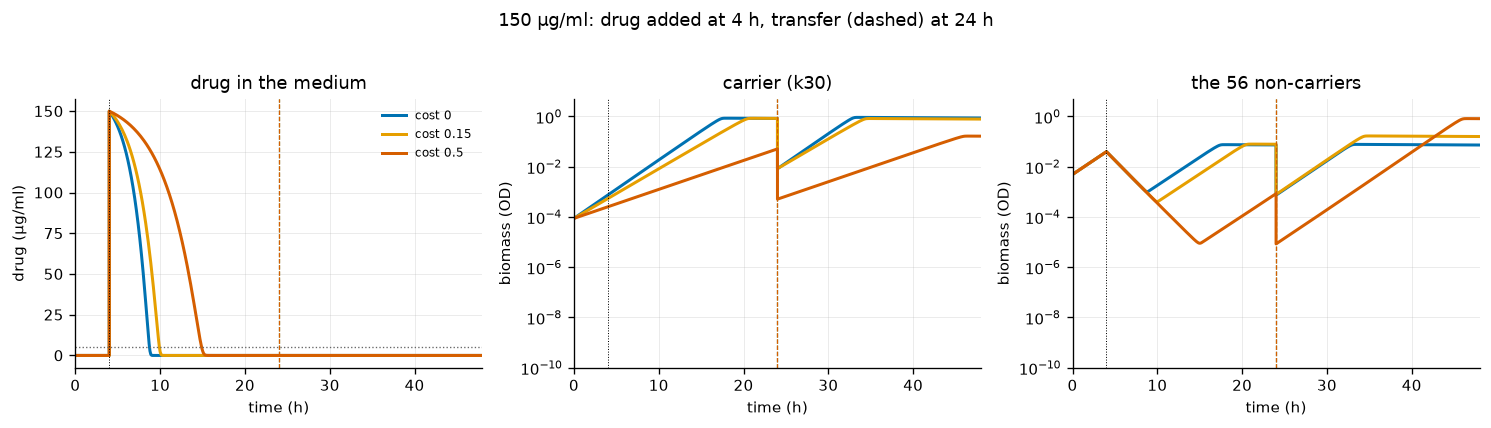

In [6]:
def timecourse(changes_list, labels, colors, name, title, tmax=None):
    fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.4))
    for ch, lab, col in zip(changes_list, labels, colors):
        r = run(**ch); sim = r.treated; p = r.params
        t, N, car = sim["t"], sim["N"], sim["carrier"]
        kw = dict(color=col, lw=1.8, label=lab)
        axs[0].plot(t, sim["a"], **kw)
        axs[1].plot(t, np.maximum(N[:, car].sum(1), 1e-10), **kw)
        axs[2].plot(t, np.maximum(N[:, ~car].sum(1), 1e-10), **kw)
        for ax in axs:
            ax.axvline(p.pregrowth_h + p.treatment_h, color=col, lw=.7, ls="--")
    axs[0].axhline(BASELINE.susceptible_ic50, color="0.4", lw=.8, ls=":")
    axs[0].set(ylabel="drug (µg/ml)", title="drug in the medium")
    axs[1].set(yscale="log", ylim=(1e-10, 5), ylabel="biomass (OD)", title="carrier (k30)")
    axs[2].set(yscale="log", ylim=(1e-10, 5), ylabel="biomass (OD)", title="the 56 non-carriers")
    for ax in axs:
        ax.axvline(BASELINE.pregrowth_h, color="k", lw=.6, ls=":")
        ax.set_xlabel("time (h)")
        if tmax: ax.set_xlim(0, tmax)
    axs[0].legend(frameon=False, fontsize=7)
    fig.suptitle(title, y=1.03); fig.tight_layout(); save(fig, name); plt.show()


timecourse([dict(dose=150.0, resistance_cost=c) for c in (0.0, 0.15, 0.5)],
           ["cost 0", "cost 0.15", "cost 0.5"], [BLUE, ORANGE, VERMILION],
           "04_cost_timecourse_150",
           "150 µg/ml: drug added at 4 h, transfer (dashed) at 24 h", tmax=48)

### What the time course shows

At 150 µg/ml:
- **Cost 0:** the carrier clears the drug in about 5 h. The non-carriers bottom out at about 10⁻³ OD, and the carrier, unaffected, has already grown to most of the culture's biomass.
- **Cost 0.15:** clearance is slower and the non-carriers' dip is deeper, but they recover.
- **Cost 0.5:** the carrier is still small when the drug arrives. Clearance takes about 11 h and the non-carriers fall further. But the carrier is also slow to fill the culture, so after the drug is gone the non-carriers regrow into nutrient the carrier has not yet used. They end up dominating, which is why compositional resilience is 0.81 rather than 0.10.

## 1.5 Does the cost act the same way for other kinds of carrier?

The cost sweep at the lab's two doses for four kinds of carrier:
- the baseline immune degrader;
- a partly protected carrier (`carrier_lysis = 0.8`), which in `test_protection_mechanism/` rescued everyone at 50 µg/ml without taking over;
- five immune carriers instead of one, all paying the cost;
- a weaker enzyme (`vmax = 3000`, a third of the default).

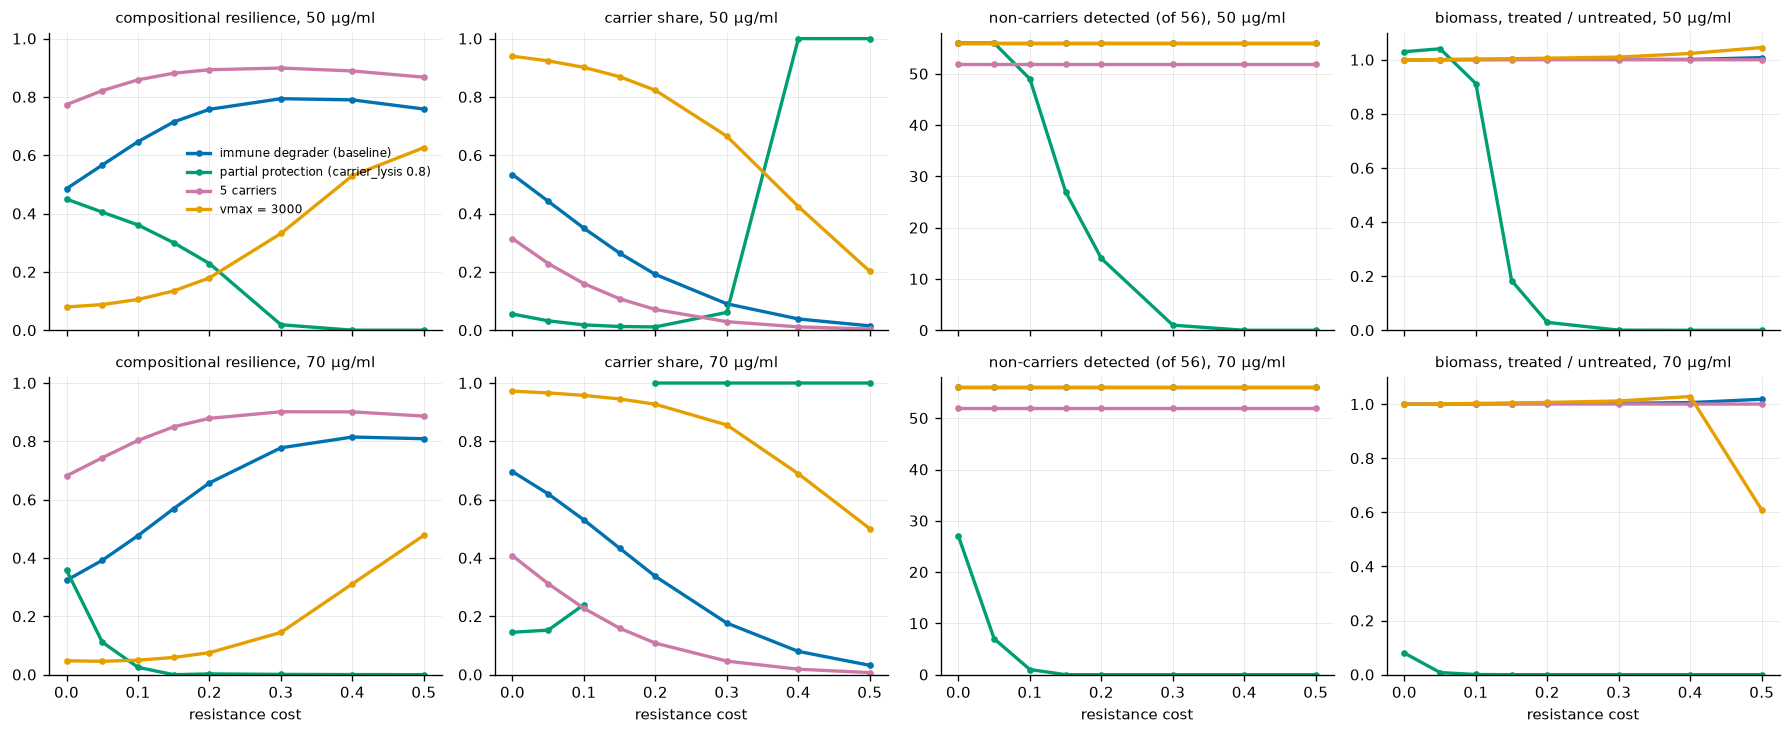

In [7]:
SCEN = {"immune degrader (baseline)": {},
        "partial protection (carrier_lysis 0.8)": dict(carrier_lysis=0.8),
        "5 carriers": dict(n_resistant=5),
        "vmax = 3000": dict(vmax=3000.0)}
SCOL = dict(zip(SCEN, [BLUE, GREEN, PURPLE, ORANGE]))
SC_COSTS = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]
scen_cost = table("05_cost_by_carrier_type.csv", lambda: [
    {"carrier": n, **row} for n, kw in SCEN.items()
    for row in runs([dict(resistance_cost=c, dose=d, **kw) for d in (50.0, 70.0)
                     for c in SC_COSTS])])

fig, axs = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True)
cols = [("compositional_resilience", "compositional resilience", (0, 1.02)),
        ("carrier_share", "carrier share", (0, 1.02)),
        ("protected_richness", "non-carriers detected (of 56)", (0, 58)),
        ("biomass_resilience", "biomass, treated / untreated", (0, 1.1))]
for i, d in enumerate((50.0, 70.0)):
    for j, (c, lab, lim) in enumerate(cols):
        ax = axs[i, j]
        for n in SCEN:
            s = scen_cost[(scen_cost.carrier == n) & (scen_cost.dose == d)]
            ax.plot(s.resistance_cost, s[c], "-o", ms=3, color=SCOL[n], label=n)
        ax.set_ylim(*lim); ax.set_title(f"{lab}, {d:g} µg/ml", fontsize=9)
        if i == 1: ax.set_xlabel("resistance cost")
axs[0, 0].legend(frameon=False, fontsize=7)
fig.tight_layout(); save(fig, "05_cost_by_carrier_type"); plt.show()

### Different carriers, different answers

- **Immune degrader:** the cost only lowers takeover. Compositional resilience climbs from 0.49 to 0.79 at 50 µg/ml, with all 56 strains surviving throughout.
- **Five immune carriers:** same direction, but smaller and saturating. Five carriers clear the drug in 1–4 h even at cost 0.5, so the cost costs nothing in rescue. Compositional resilience rises from 0.77 to about 0.90 at both doses.
- **Weaker enzyme (`vmax = 3000`):** the cost helps most here. With a cheap carrier, clearance takes 5–6 h and the carrier ends at more than 90% of the community. A cost of 0.5 cuts that to 20% at 50 µg/ml. At 70 µg/ml with cost 0.5, biomass recovery starts to suffer (0.61).
- **Partly protected carrier (`carrier_lysis 0.8`):** the cost is purely harmful. At 50 µg/ml, survivors fall from 56 to 27 at cost 0.15 and to none at cost 0.4. At 70 µg/ml, even cost 0.05 leaves only 7.

**Rule:** whether a fitness cost helps or hurts the community depends on **whether the rescue has margin**. With margin (immune, enough enzyme), the cost limits takeover and improves composition. Without margin (partial protection, high dose), the cost is the difference between rescue and collapse.

## 1.6 Robustness across trait draws

The same questions for 12 trait draws (`seed`). Each draw gives the 57 strains new growth rates and IC50s, so k30's own growth rate differs too. For each seed and dose, the table reports the cost that maximizes compositional resilience, the resilience gain over the 0.05 baseline, and whether a cost of 0.5 breaks full rescue at 280 µg/ml.

       best_cost_median  best_cost_min  best_cost_max  gain_median  seeds_rescued_cost_005  seeds_rescued_cost_05
dose                                                                                                             
20.0               0.00           0.00            0.2        0.006                      12                     12
50.0               0.25           0.15            0.4        0.121                      12                     12
150.0              0.50           0.50            0.5        0.650                      12                     12
280.0              0.50           0.40            0.5        0.272                      11                      3


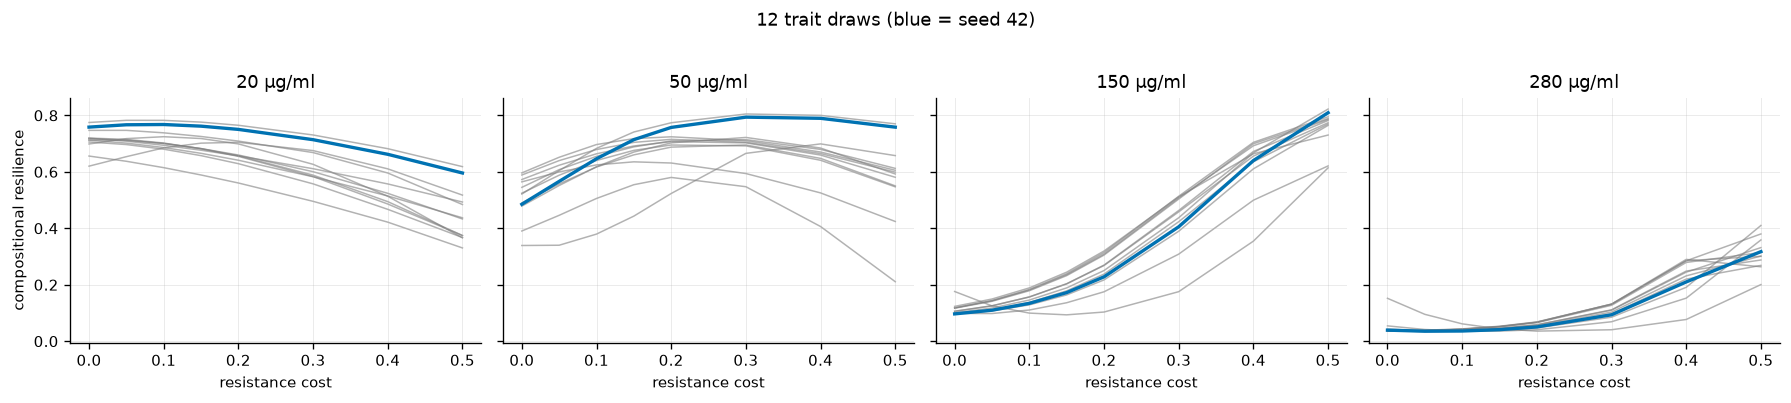

In [8]:
SEEDS = [1, 3, 7, 11, 19, 23, 42, 55, 77, 99, 123, 2024]
ROB_COSTS = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]
rob = table("06_cost_seed_robustness.csv", lambda: runs(
    [dict(seed=s, resistance_cost=c, dose=d) for s in SEEDS for d in (20.0, 50.0, 150.0, 280.0)
     for c in ROB_COSTS]))
rob["full_rescue"] = (rob.protected_richness == 56) & (rob.biomass_resilience >= 0.9)

summ = []
for (s, d), g in rob.groupby(["seed", "dose"]):
    b = g.loc[g.compositional_resilience.idxmax()]
    base = g[g.resistance_cost == 0.05].iloc[0]
    summ.append(dict(seed=s, dose=d, best_cost=b.resistance_cost,
                     gain_over_cost_005=b.compositional_resilience - base.compositional_resilience,
                     rescue_at_cost_05=bool(g[g.resistance_cost == 0.5].full_rescue.iloc[0]),
                     rescue_at_cost_005=bool(base.full_rescue)))
summ = pd.DataFrame(summ)
summ.to_csv(OUT / "06_cost_seed_summary.csv", index=False)
print(summ.groupby("dose").agg(
    best_cost_median=("best_cost", "median"), best_cost_min=("best_cost", "min"),
    best_cost_max=("best_cost", "max"), gain_median=("gain_over_cost_005", "median"),
    seeds_rescued_cost_005=("rescue_at_cost_005", "sum"),
    seeds_rescued_cost_05=("rescue_at_cost_05", "sum")).round(3).to_string())

fig, axs = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, d in zip(axs, (20.0, 50.0, 150.0, 280.0)):
    for s in SEEDS:
        g = rob[(rob.seed == s) & (rob.dose == d)]
        ax.plot(g.resistance_cost, g.compositional_resilience, color=BLUE if s == 42 else GREY,
                lw=2 if s == 42 else 0.9, alpha=1 if s == 42 else 0.6, zorder=3 if s == 42 else 1)
    ax.set(title=f"{d:g} µg/ml", xlabel="resistance cost")
axs[0].set_ylabel("compositional resilience")
fig.suptitle("12 trait draws (blue = seed 42)", y=1.03)
fig.tight_layout(); save(fig, "06_cost_seed_robustness"); plt.show()

### Robustness across trait draws

The pattern holds across all 12 draws. The best cost is:
- 0 at 20 µg/ml (median; range 0–0.2);
- 0.25 at 50 µg/ml (range 0.15–0.4);
- 0.5 at 150 µg/ml in every draw;
- 0.4–0.5 at 280 µg/ml.

The median gain in compositional resilience over the 0.05 baseline is +0.12 at 50 µg/ml and +0.65 at 150 µg/ml.

At 280 µg/ml, full rescue with all 56 detected holds in 11 of 12 draws at cost 0.05 but only 3 of 12 at cost 0.5. The collapse at high dose and high cost is a robust feature, not a quirk of seed 42.

The exact best cost shifts from draw to draw. Each draw also changes k30's own growth rate, which should act like a shift in cost through the same carrier-growth route found in `test_resistance_distribution/` and `test_protection_mechanism/`. That attribution is expected, not separately tested here.

# Part 2. Treatment duration

`treatment_h` is how long the community sits in drug before the 1:100 transfer into fresh, drug-free medium. Two features of the protocol, as modelled, shape what duration can do:

- **The transfer removes the drug completely.** The spent medium is discarded and the recovery phase starts at zero drug. A real 1:100 transfer would carry over 1% of the remaining drug (0.5 µg/ml after a 50 µg/ml treatment that was never degraded). That is below the median IC50 of 5 µg/ml, but above the IC50 of the most sensitive strains.
- **Killing needs growth.** Once the nutrient runs out, the drug stops killing even if it is still present.

The protocol's 20 h treatment is the reference.

## 2.1 Duration at five doses, baseline carrier

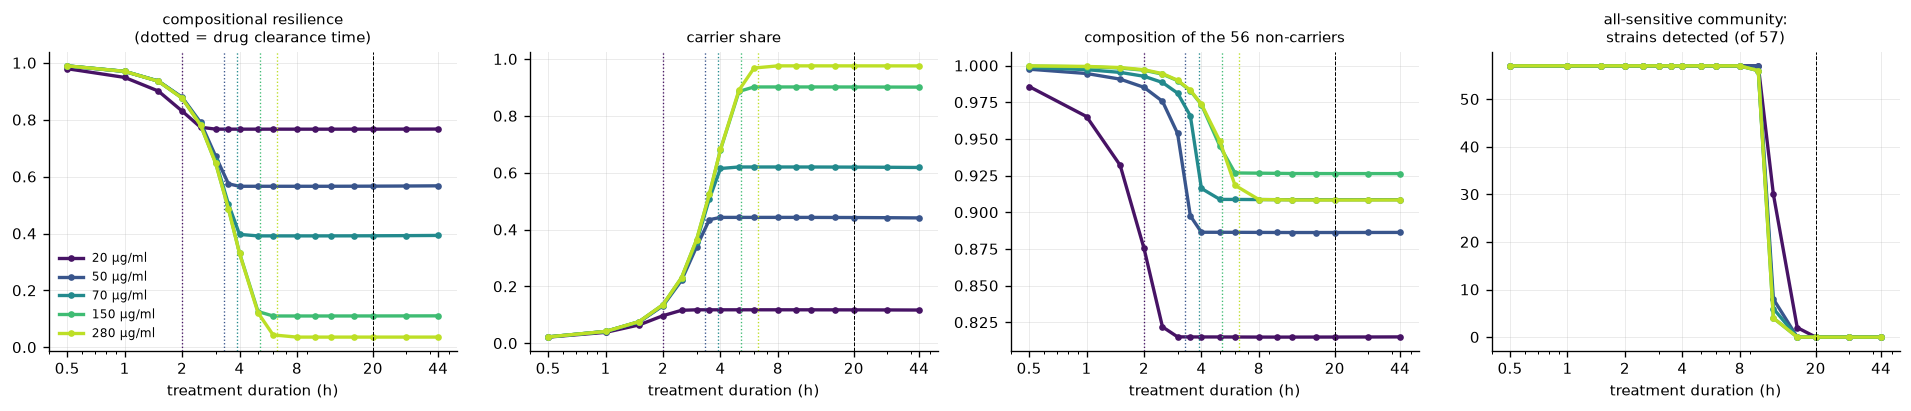

 dose  treatment_h  compositional_resilience  carrier_share  protected_richness  sensitive_richness  drug_at_transfer
 50.0          0.5                     0.989          0.022                56.0                57.0            46.552
 50.0          1.0                     0.970          0.041                56.0                57.0            42.145
 50.0          1.5                     0.936          0.075                56.0                57.0            36.540
 50.0          2.0                     0.879          0.132                56.0                57.0            29.478
 50.0          2.5                     0.790          0.221                56.0                57.0            20.764
 50.0          3.0                     0.672          0.340                56.0                57.0            10.667
 50.0          3.5                     0.575          0.435                56.0                57.0             1.993
 50.0          4.0                     0.566          0.

In [9]:
DURS = [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 8, 10, 12, 16, 20, 30, 44]
DUR_DOSES = [20.0, 50.0, 70.0, 150.0, 280.0]
dur = table("07_duration_x_dose.csv", lambda: runs(
    [dict(treatment_h=float(T), dose=d) for d in DUR_DOSES for T in DURS]))
clear20 = cost_grid[cost_grid.resistance_cost == 0.05].set_index("dose").drug_clearance_h

ddc = dict(zip(DUR_DOSES, plt.cm.viridis(np.linspace(0.05, 0.9, len(DUR_DOSES)))))
fig, axs = plt.subplots(1, 4, figsize=(16, 3.5))
for d in DUR_DOSES:
    s = dur[dur.dose == d]
    kw = dict(color=ddc[d], marker="o", ms=3, label=f"{d:g} µg/ml")
    axs[0].plot(s.treatment_h, s.compositional_resilience, **kw)
    axs[1].plot(s.treatment_h, s.carrier_share, **kw)
    axs[2].plot(s.treatment_h, s.protected_composition, **kw)
    axs[3].plot(s.treatment_h, s.sensitive_richness, **kw)
    if d in clear20.index:
        for ax in axs[:3]:
            ax.axvline(clear20[d], color=ddc[d], lw=0.8, ls=":")
for ax, t in zip(axs, ["compositional resilience\n(dotted = drug clearance time)",
                       "carrier share", "composition of the 56 non-carriers",
                       "all-sensitive community:\nstrains detected (of 57)"]):
    ax.set_title(t, fontsize=9); ax.set_xscale("log"); ax.set_xlabel("treatment duration (h)")
    ax.axvline(20, color="k", lw=0.6, ls="--")
    ax.set_xticks([0.5, 1, 2, 4, 8, 20, 44]); ax.set_xticklabels(["0.5", "1", "2", "4", "8", "20", "44"])
axs[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); save(fig, "07_duration_x_dose"); plt.show()
print(dur[dur.dose.isin([50.0, 150.0])][["dose", "treatment_h", "compositional_resilience",
      "carrier_share", "protected_richness", "sensitive_richness", "drug_at_transfer"]]
      .round(3).to_string(index=False))

### What duration does when the carrier clears the drug

**The composition after recovery is set within the first few hours of treatment.**
- Compositional resilience falls steeply as duration increases from 0.5 h (0.99) to the clearance time: about 3.5–4 h at 50 µg/ml and 5–6 h at 150 µg/ml (dotted lines).
- After that it is **flat**: 0.57 at 50 µg/ml and 0.11 at 150 µg/ml, whether the transfer comes at 4, 20 or 44 h.
- Once the carrier has removed the drug, extra time in the spent medium changes nothing the matched control does not also experience.
- The loss of composition is essentially all carrier enrichment: carrier share rises from 2% to 44% (50 µg/ml) or 90% (150 µg/ml). The non-carriers' own composition stays high.

**Short treatments help because the transfer removes the drug.** A 1–2 h treatment followed by transfer to fresh medium cuts killing short before the carrier has time to take over. This depends on the modelled transfer discarding all drug (see the caveat at the top of Part 2).

**The all-sensitive community has a duration threshold.**
- It is still fully detected after 8–10 h of treatment, at any dose from 50 to 150 µg/ml.
- It is down to 4–8 strains at 12 h and gone by 16 h.
- Because killing needs growth, the drug only kills while cells have nutrient to grow on. A culture being killed down uses little nutrient, so killing continues until the strains fall below about 100 cells. The 1:100 transfer then takes them below one cell.

**Practical reading:**
- With an effective degrader, the protocol's 20 h is far past the point where duration matters. Shortening it to anything above the clearance time would not change the measured composition.
- Without a degrader, duration is decisive between about 8 and 16 h.

## 2.2 The full duration × dose map

For the community with the carrier, and for the matched all-sensitive community.

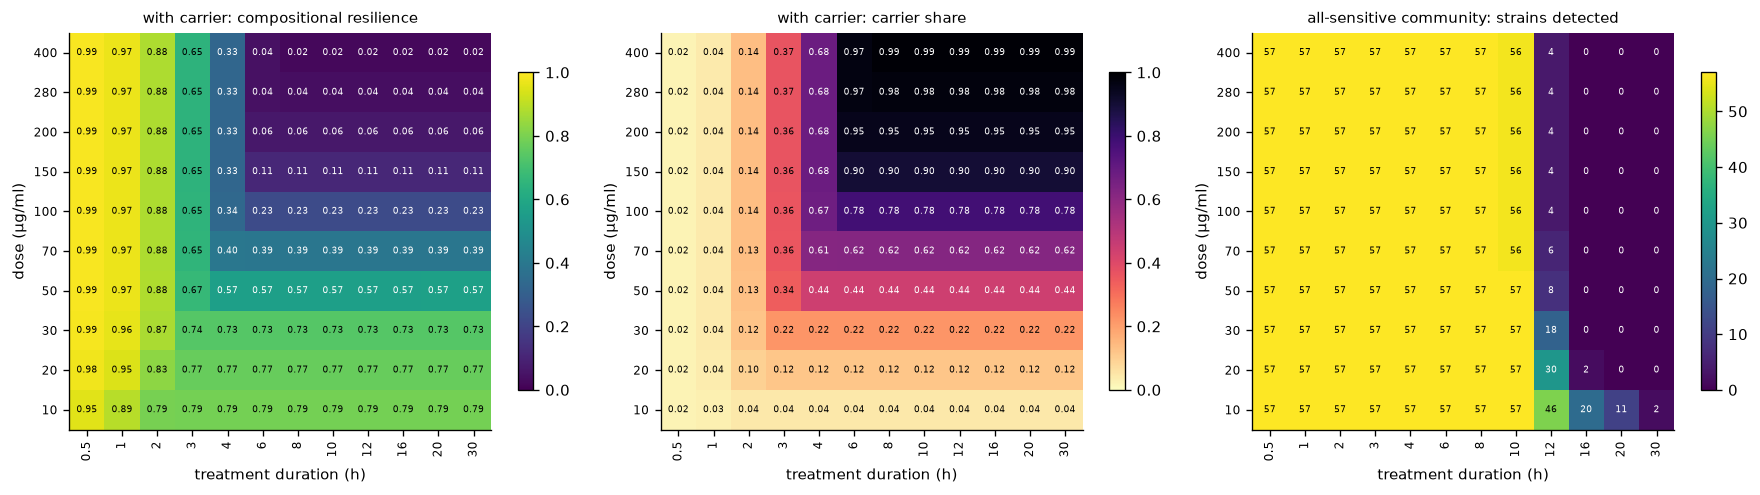

In [10]:
HM_DURS = [0.5, 1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 30]
HM_DOSES = [10.0, 20.0, 30.0, 50.0, 70.0, 100.0, 150.0, 200.0, 280.0, 400.0]
dur_map = table("08_duration_dose_map.csv", lambda: runs(
    [dict(treatment_h=float(T), dose=d) for d in HM_DOSES for T in HM_DURS]))
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (z, t, cmap, lo, hi, fmt) in zip(axs, [
        ("compositional_resilience", "with carrier: compositional resilience", "viridis", 0, 1, "{:.2f}"),
        ("carrier_share", "with carrier: carrier share", "magma_r", 0, 1, "{:.2f}"),
        ("sensitive_richness", "all-sensitive community: strains detected", "viridis", 0, 57, "{:.0f}")]):
    im = heatmap(ax, dur_map, "treatment_h", "dose", z, cmap, lo, hi, fmt,
                 xlabel="treatment duration (h)", ylabel="dose (µg/ml)", title=t)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); save(fig, "08_duration_dose_map"); plt.show()

### The map

**With the carrier:**
- Composition is preserved only for treatments shorter than the clearance time. The higher the dose, the longer that time, so the boundary slopes up and to the right.
- Above it, the end-point composition depends on dose alone.

**Without the carrier:**
- Survival is set almost entirely by duration: 56–57 strains are detected through 10 h, and essentially none from 16 h on.
- Above about 50 µg/ml, dose barely matters. At 50–400 µg/ml every strain is far above its IC50, so killing is at its maximum, which is proportional to growth (`gamma · g`), and higher doses cannot kill faster.
- Below that, at 10–30 µg/ml, the least sensitive strains survive longer.

## 2.3 When the drug lingers: duration with weaker protection

Duration can only matter while there is drug left to act. The baseline carrier clears the drug within a few hours, so this section repeats the sweep with carriers that clear it more slowly or not at all:
- a weaker enzyme (`vmax = 1000`), which in `test_protection_mechanism/` saved only 17 of 56;
- a partly protected carrier (`carrier_lysis = 0.8`) at 70 µg/ml, where it failed;
- a non-immune degrader (`carrier_lysis = 1`) at 50 µg/ml;
- a costly carrier (`resistance_cost = 0.3`) at 280 µg/ml.

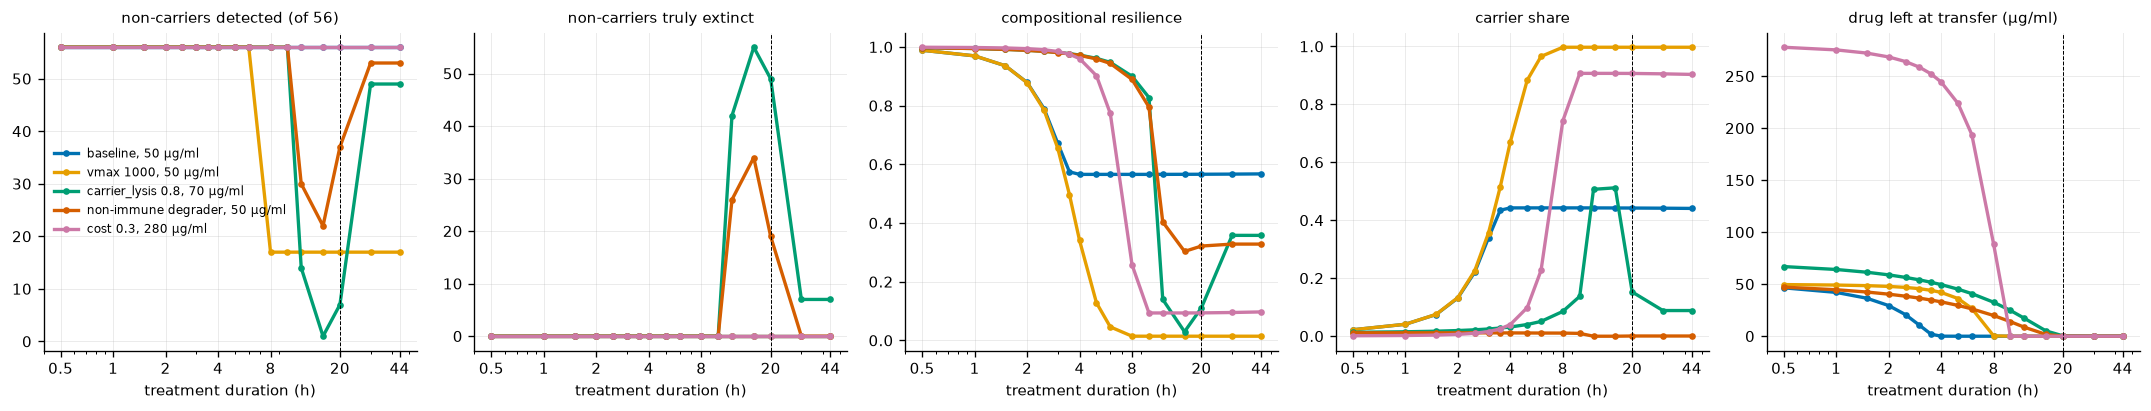

                     scenario  treatment_h  protected_richness  protected_extinct  compositional_resilience  carrier_share  drug_at_transfer
           baseline, 50 µg/ml          1.0                56.0                0.0                     0.970          0.041            42.145
           baseline, 50 µg/ml          2.0                56.0                0.0                     0.879          0.132            29.478
           baseline, 50 µg/ml          4.0                56.0                0.0                     0.566          0.443             0.040
           baseline, 50 µg/ml          8.0                56.0                0.0                     0.566          0.443            -0.000
           baseline, 50 µg/ml         12.0                56.0                0.0                     0.566          0.443            -0.000
           baseline, 50 µg/ml         20.0                56.0                0.0                     0.567          0.442            -0.000
           ba

In [11]:
DSCEN = {"baseline, 50 µg/ml": dict(dose=50.0),
         "vmax 1000, 50 µg/ml": dict(dose=50.0, vmax=1000.0),
         "carrier_lysis 0.8, 70 µg/ml": dict(dose=70.0, carrier_lysis=0.8),
         "non-immune degrader, 50 µg/ml": dict(dose=50.0, carrier_lysis=1.0),
         "cost 0.3, 280 µg/ml": dict(dose=280.0, resistance_cost=0.3)}
DCOL = dict(zip(DSCEN, [BLUE, ORANGE, GREEN, VERMILION, PURPLE]))
dscen = table("09_duration_by_scenario.csv", lambda: [
    {"scenario": n, **row} for n, kw in DSCEN.items()
    for row in runs([dict(treatment_h=float(T), **kw) for T in DURS])])

fig, axs = plt.subplots(1, 5, figsize=(18, 3.5))
for n in DSCEN:
    s = dscen[dscen.scenario == n]
    kw = dict(color=DCOL[n], marker="o", ms=3, label=n)
    axs[0].plot(s.treatment_h, s.protected_richness, **kw)
    axs[1].plot(s.treatment_h, s.protected_extinct, **kw)
    axs[2].plot(s.treatment_h, s.compositional_resilience, **kw)
    axs[3].plot(s.treatment_h, s.carrier_share, **kw)
    axs[4].plot(s.treatment_h, s.drug_at_transfer, **kw)
for ax, t in zip(axs, ["non-carriers detected (of 56)", "non-carriers truly extinct",
                       "compositional resilience", "carrier share", "drug left at transfer (µg/ml)"]):
    ax.set_title(t, fontsize=9); ax.set_xscale("log"); ax.set_xlabel("treatment duration (h)")
    ax.axvline(20, color="k", lw=0.6, ls="--")
    ax.set_xticks([0.5, 1, 2, 4, 8, 20, 44]); ax.set_xticklabels(["0.5", "1", "2", "4", "8", "20", "44"])
axs[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); save(fig, "09_duration_by_scenario"); plt.show()
cols_show = ["scenario", "treatment_h", "protected_richness", "protected_extinct",
             "compositional_resilience", "carrier_share", "drug_at_transfer"]
print(dscen[dscen.treatment_h.isin([1, 2, 4, 8, 12, 20, 44])][cols_show].round(3).to_string(index=False))

### When the drug lingers, duration matters, and not monotonically

**Weaker enzyme (`vmax 1000`, 50 µg/ml):**
- Treatments shorter than 4 h keep all 56 strains, because the transfer ends exposure before the drug has done its damage.
- From 8 h on, 39 strains drop below detection and the carrier ends at 99.7%.
- None of these strains is truly extinct: they are swamped, not killed.

**Partial protection (`carrier_lysis 0.8`, 70 µg/ml) and the non-immune degrader (50 µg/ml):** these show a **worst duration**.

| Treatment | `carrier_lysis 0.8`, 70 µg/ml | Non-immune degrader, 50 µg/ml |
|---|---|---|
| ≤ 8 h | all survive | all survive |
| 12–16 h | 42–55 strains extinct | 26–34 strains extinct |
| 20 h (the protocol) | 49 extinct | 19 extinct |
| 30–44 h | 7 extinct | none extinct |

The cause is the **transfer bottleneck**:
- The 1:100 dilution removes any strain that has fewer than 100 cells at the transfer.
- In these runs the drug is cleared slowly, around 12–20 h, and the non-carriers spend that time at their minimum, a few hundred cells or fewer per strain.
- A transfer then catches them at the bottom.
- A long treatment lets them regrow in the spent medium, which still has nutrient because so much of the community died, before they are diluted.
- At 24 h the 20 h and 44 h runs are identical: non-carriers total 3.2×10⁻⁶ OD. By the 44 h transfer they have regrown to 0.8 OD.

**Costly carrier (cost 0.3, 280 µg/ml):** the same clearance-time plateau as the baseline, shifted to about 12 h, because the costly carrier clears more slowly.

**General rule:** treatment duration matters only up to the time the drug is cleared. Its effect is worst when the transfer falls close to the trough of the susceptible populations. **What matters is when the bottleneck falls relative to drug clearance, not exposure time as such.**

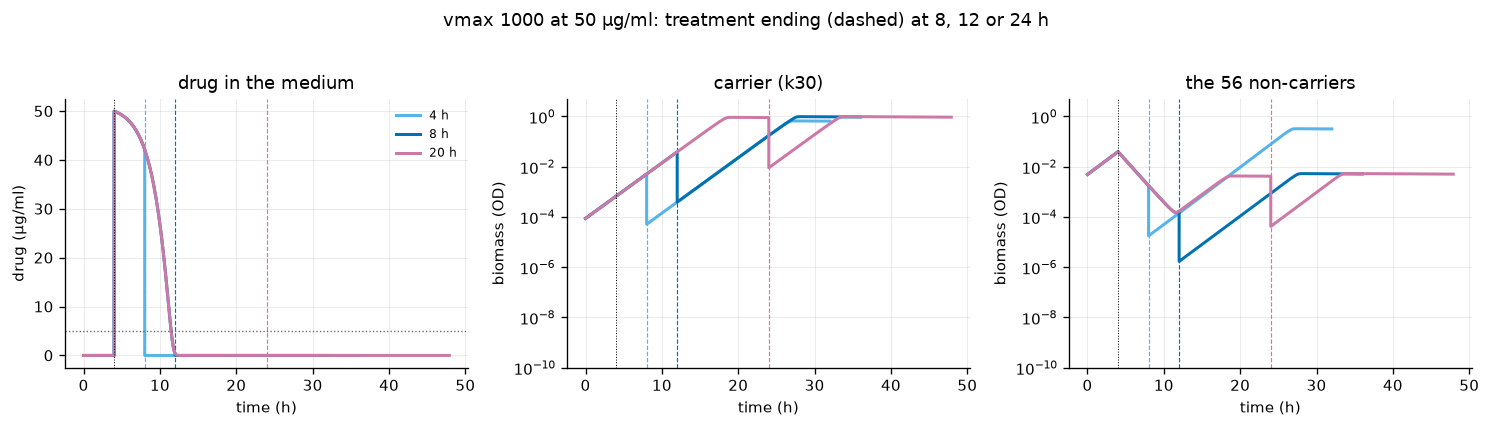

In [12]:
timecourse([dict(dose=50.0, vmax=1000.0, treatment_h=T) for T in (4.0, 8.0, 20.0)],
           ["4 h", "8 h", "20 h"], [SKY, BLUE, PURPLE], "10_duration_timecourse_vmax1000",
           "vmax 1000 at 50 µg/ml: treatment ending (dashed) at 8, 12 or 24 h")

The same culture under three treatment lengths. Up to each transfer (dashed) the runs are identical. A 4 h treatment transfers the community while the drug is still at about 42 µg/ml, but before much killing has happened. An 8 h treatment transfers near the non-carriers' minimum. A 20 h treatment transfers after the drug is gone and the carrier has taken the culture.

## 2.4 Cost and duration together

A higher cost slows drug clearance (Part 1), which should widen the window in which duration matters. This is the duration sweep at 150 µg/ml for four costs.

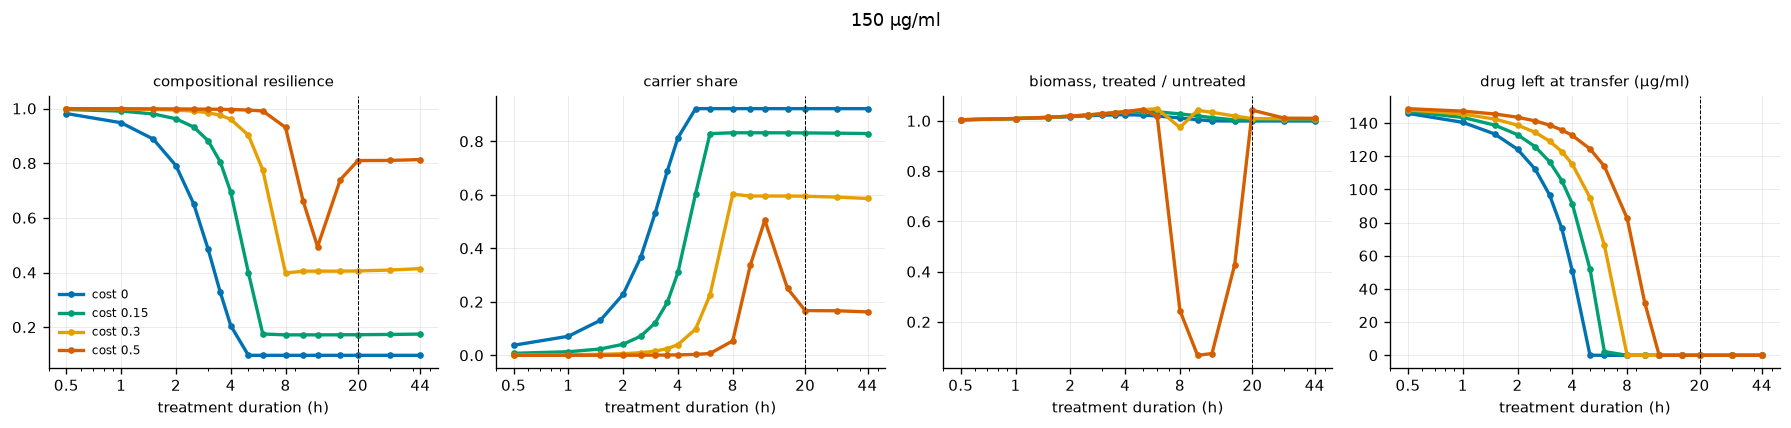

In [13]:
CD_COSTS = [0.0, 0.15, 0.3, 0.5]
cd = table("11_cost_x_duration.csv", lambda: runs(
    [dict(resistance_cost=c, treatment_h=float(T), dose=150.0) for c in CD_COSTS for T in DURS]))
ccol = dict(zip(CD_COSTS, [BLUE, GREEN, ORANGE, VERMILION]))
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
for c in CD_COSTS:
    s = cd[cd.resistance_cost == c]
    kw = dict(color=ccol[c], marker="o", ms=3, label=f"cost {c:g}")
    axs[0].plot(s.treatment_h, s.compositional_resilience, **kw)
    axs[1].plot(s.treatment_h, s.carrier_share, **kw)
    axs[2].plot(s.treatment_h, s.biomass_resilience, **kw)
    axs[3].plot(s.treatment_h, s.drug_at_transfer, **kw)
for ax, t in zip(axs, ["compositional resilience", "carrier share",
                       "biomass, treated / untreated", "drug left at transfer (µg/ml)"]):
    ax.set_title(t, fontsize=9); ax.set_xscale("log"); ax.set_xlabel("treatment duration (h)")
    ax.axvline(20, color="k", lw=0.6, ls="--")
    ax.set_xticks([0.5, 1, 2, 4, 8, 20, 44]); ax.set_xticklabels(["0.5", "1", "2", "4", "8", "20", "44"])
axs[0].legend(frameon=False, fontsize=7)
fig.suptitle("150 µg/ml", y=1.03)
fig.tight_layout(); save(fig, "11_cost_x_duration"); plt.show()

### Cost and duration interact through clearance time

At 150 µg/ml:
- **Cost 0 to 0.3:** each curve has the same shape, a fall that plateaus at its own clearance time. A higher cost moves the plateau later (≈ 6 h at cost 0, 8 h at 0.3) and higher, because there is less takeover (0.10 → 0.41).
- **Cost 0.5:** the curve is not monotonic. Treatments of 8–12 h transfer the community at its lowest point, with biomass recovery of only 0.25 and 0.07. A 20 h treatment lets it regrow first, giving compositional resilience 0.81.

A costly carrier therefore makes the outcome **more sensitive to treatment duration**: it lengthens the window in which the timing of the transfer decides the result.

## 2.5 Robustness across trait draws

For the same 12 seeds:
- the duration after which the baseline community's composition stops changing, defined as the first duration within 0.01 of the 44 h value;
- the longest duration after which all 57 strains of the all-sensitive community are still detected;
- the first duration at which the all-sensitive community is lost entirely.

In [14]:
ROB_DURS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 44]
rob_d = table("12_duration_seed_robustness.csv", lambda: runs(
    [dict(seed=s, treatment_h=float(T), dose=d) for s in SEEDS for d in (50.0, 150.0)
     for T in ROB_DURS]))
rows = []
for (s, d), g in rob_d.groupby(["seed", "dose"]):
    g = g.sort_values("treatment_h")
    final = g.compositional_resilience.iloc[-1]
    plateau = g[np.abs(g.compositional_resilience - final) < 0.01].treatment_h.min()
    full = g[g.sensitive_richness == 57].treatment_h
    gone = g[g.sensitive_richness == 0].treatment_h
    rows.append(dict(seed=s, dose=d, plateau_h=plateau,
                     clearance_h=float(g[g.treatment_h == 20].drug_clearance_h.iloc[0]),
                     composition_at_1h=g[g.treatment_h == 1].compositional_resilience.iloc[0],
                     composition_at_20h=g[g.treatment_h == 20].compositional_resilience.iloc[0],
                     sensitive_all_detected_up_to_h=full.max() if len(full) else np.nan,
                     sensitive_lost_from_h=gone.min() if len(gone) else np.nan))
rob_ds = pd.DataFrame(rows)
rob_ds.to_csv(OUT / "12_duration_seed_summary.csv", index=False)
print(rob_ds.groupby("dose").agg(["median", "min", "max"]).drop(columns="seed").round(2).T.to_string())

dose                                   50.0   150.0
plateau_h                      median   4.00   6.00
                               min      3.00   4.00
                               max      4.00   6.00
clearance_h                    median   3.40   5.30
                               min      2.50   3.90
                               max      3.60   5.60
composition_at_1h              median   0.97   0.98
                               min      0.80   0.79
                               max      0.98   0.98
composition_at_20h             median   0.59   0.13
                               min      0.34   0.10
                               max      0.65   0.15
sensitive_all_detected_up_to_h median  10.00   8.00
                               min      8.00   8.00
                               max     10.00  10.00
sensitive_lost_from_h          median  16.00  16.00
                               min     16.00  16.00
                               max     20.00  16.00


### Robustness

Across all 12 trait draws:

| Quantity | 50 µg/ml | 150 µg/ml |
|---|---|---|
| Composition stops changing (plateau), median | 4 h (range 3–4) | 6 h (range 4–6) |
| Drug clearance, median | 3.4 h | 5.3 h |
| All-sensitive community fully detected up to | 8–10 h | 8–10 h |
| All-sensitive community entirely lost from | 16–20 h | 16 h |
| Compositional resilience, 1 h treatment, median | 0.97 | 0.98 |
| Compositional resilience, 20 h treatment, median | 0.59 | 0.13 |

The plateau follows the clearance time: its median is within about half an hour of the median clearance time at both doses.

# Part 3. Who is lost: growth rate vs. IC50

For β-lactams, faster-growing cells are killed faster. The model builds this in: a susceptible strain's killing rate is `gamma · f(drug/IC50) · g`, where `g` is its *current* growth rate. That rate is its intrinsic `mu` slowed by nutrient limitation and lag (`resilience_model.py`, `_rates`). So two strain traits decide who suffers most:

- intrinsic growth rate `mu`: strains differ by about 8% (`growth_cv`);
- IC50: strains differ about 9-fold, 5th to 95th percentile (`ic50_cv = 0.7`).

For each run, every non-carrier **still alive** at the end of recovery gets a log10 fold change, treated ÷ untreated. That fold change is rank-correlated with each trait. Extinct strains are left out, because an extinct strain's "fold change" just mirrors its untreated abundance. ρ is reported only when at least 10 strains remain. A negative ρ with `mu` means faster growers are lost preferentially; a positive ρ with IC50 means the more tolerant strains fare better.

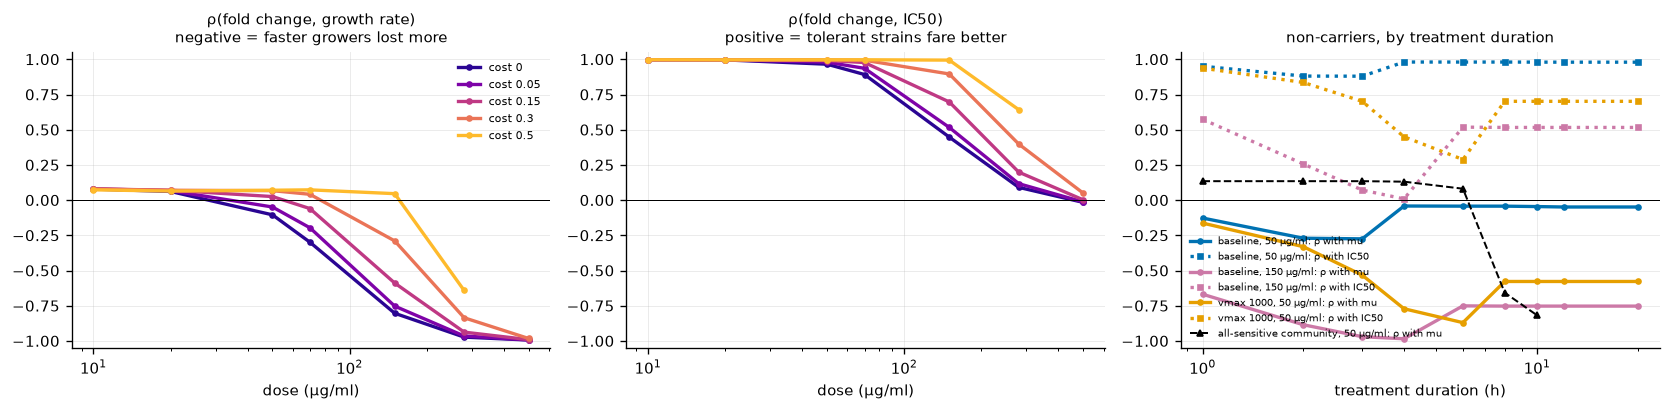

 resistance_cost  dose  resistant_rho_mu  resistant_rho_ic50  resistant_lfc_spread  resistant_n_alive  sensitive_rho_mu  sensitive_rho_ic50  sensitive_lfc_spread  sensitive_n_alive
            0.00  10.0              0.08                1.00                  0.75                 56              0.17                0.98                  3.17                 11
            0.00  20.0              0.06                1.00                  0.73                 56               NaN                 NaN                  0.00                  0
            0.00  50.0             -0.10                0.97                  0.48                 56               NaN                 NaN                  0.00                  0
            0.00  70.0             -0.30                0.89                  0.39                 56               NaN                 NaN                  0.00                  0
            0.00 150.0             -0.80                0.45                  0.34             

In [15]:
from scipy.stats import spearmanr


def selectivity(r):
    p = r.params
    t_end = p.pregrowth_h + p.treatment_h + p.recovery_h
    car = r.treated["carrier"]
    out = {}
    for comm in ("resistant", "sensitive"):
        trt, ctl = r.runs[(comm, True)], r.runs[(comm, False)]
        keep = ~car if comm == "resistant" else np.ones_like(car)
        xt = snapshot(trt, t_end)
        # only strains still alive: an extinct strain's fold change is just minus its control
        # abundance, which would rank it by growth rate whatever the drug did
        keep = keep & (xt > 0)
        lfc = np.log10(xt / snapshot(ctl, t_end))[keep]
        mu = trt["mu"][keep]; ic = trt["ic50"][keep]
        spread = lfc.max() - lfc.min() if keep.sum() else 0.0
        ok = keep.sum() >= 10 and spread > 1e-3   # need enough strains, and some difference
        out[f"{comm}_rho_mu"] = spearmanr(lfc, mu)[0] if ok else np.nan
        out[f"{comm}_rho_ic50"] = spearmanr(lfc, ic)[0] if ok else np.nan
        out[f"{comm}_lfc_spread"] = spread
        out[f"{comm}_n_alive"] = int(keep.sum())
    return out


SEL_DOSES = [10.0, 20.0, 50.0, 70.0, 150.0, 280.0, 500.0]
sel_cost = table("13_selectivity_cost_x_dose.csv", lambda: [
    dict(resistance_cost=c, dose=d, **selectivity(run(resistance_cost=c, dose=d)))
    for c in (0.0, 0.05, 0.15, 0.3, 0.5) for d in SEL_DOSES])
sel_dur = table("14_selectivity_duration.csv", lambda: [
    dict(scenario=n, treatment_h=float(T), **selectivity(run(treatment_h=float(T), **kw)))
    for n, kw in [("baseline, 50 µg/ml", dict(dose=50.0)),
                  ("baseline, 150 µg/ml", dict(dose=150.0)),
                  ("vmax 1000, 50 µg/ml", dict(dose=50.0, vmax=1000.0))]
    for T in [1, 2, 3, 4, 6, 8, 10, 12, 20]])
sel_cv = table("15_selectivity_growth_cv.csv", lambda: [
    dict(growth_cv=cv, dose=d, **selectivity(run(growth_cv=cv, dose=d)))
    for cv in (0.08, 0.2, 0.3) for d in (50.0, 150.0, 280.0)])

fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
ccols = dict(zip((0.0, 0.05, 0.15, 0.3, 0.5), plt.cm.plasma(np.linspace(0.05, 0.85, 5))))
for c, s in sel_cost.groupby("resistance_cost"):
    axs[0].plot(s.dose, s.resistant_rho_mu, "-o", ms=3, color=ccols[c], label=f"cost {c:g}")
    axs[1].plot(s.dose, s.resistant_rho_ic50, "-o", ms=3, color=ccols[c])
for ax, t in zip(axs[:2], ["ρ(fold change, growth rate)\nnegative = faster growers lost more",
                           "ρ(fold change, IC50)\npositive = tolerant strains fare better"]):
    ax.set(xscale="log", xlabel="dose (µg/ml)", ylim=(-1.05, 1.05)); ax.set_title(t, fontsize=9)
    ax.axhline(0, color="k", lw=0.6)
axs[0].legend(frameon=False, fontsize=6.5)
dsc = dict(zip(sel_dur.scenario.unique(), [BLUE, PURPLE, ORANGE]))
for n, s in sel_dur.groupby("scenario", sort=False):
    axs[2].plot(s.treatment_h, s.resistant_rho_mu, "-o", ms=3, color=dsc[n], label=f"{n}: ρ with mu")
    axs[2].plot(s.treatment_h, s.resistant_rho_ic50, ":", marker="s", ms=3, color=dsc[n],
                label=f"{n}: ρ with IC50")
s = sel_dur[sel_dur.scenario == "baseline, 50 µg/ml"]
axs[2].plot(s.treatment_h, s.sensitive_rho_mu, "k--", marker="^", ms=4, lw=1.2,
            label="all-sensitive community, 50 µg/ml: ρ with mu")
axs[2].set(xscale="log", xlabel="treatment duration (h)", ylim=(-1.05, 1.05))
axs[2].set_title("non-carriers, by treatment duration", fontsize=9)
axs[2].axhline(0, color="k", lw=0.6); axs[2].legend(frameon=False, fontsize=6)
fig.tight_layout(); save(fig, "12_growth_vs_ic50_selectivity"); plt.show()

with pd.option_context("display.width", 200):
    print(sel_cost.round(2).to_string(index=False))
    print(sel_dur.round(2).to_string(index=False))
    print(sel_cv.round(2).to_string(index=False))

### Who is lost depends on the dose, and growth rate takes over at high dose

**Moderate doses (≤ 70 µg/ml) with an effective carrier:**
- Which non-carriers suffer is set almost entirely by **IC50** (ρ ≈ +0.9 to +1.0), not by growth rate (|ρ| ≤ 0.3).
- The drug is close to the strains' IC50s while it is being cleared. The 9-fold IC50 spread (`ic50_cv = 0.7`) then outweighs the 8% growth-rate spread (`growth_cv = 0.08`).

**High doses (≥ 150 µg/ml):**
- Loss is set by **growth rate** (ρ = −0.75 at 150, −0.96 at 280, −0.99 at 500 µg/ml): **faster-growing strains are lost preferentially**.
- Every strain is then far above its IC50, so the dose-response term is saturated for all of them. Killing reduces to `gamma · g`, and the strain that grows fastest dies fastest. This is the β-lactam growth-rate dependence, made visible once IC50 differences no longer matter.

**Cost moves this boundary.** A costly carrier has less enzyme, so on the way down the drug spends longer in the range of the IC50s, where degradation is first-order and slow. That extends the IC50-selective phase. At 150 µg/ml, ρ with growth rate weakens from −0.75 (cost 0.05) to −0.29 (cost 0.3) and +0.05 (cost 0.5).

**Duration:**
- **Baseline carrier at 150 µg/ml:** growth rate dominates within the first 2–4 h (ρ = −0.88 to −0.98), while the drug is still saturating.
- **Weak enzyme (`vmax 1000`, 50 µg/ml):** the drug lingers, and growth-rate selection builds with longer exposure (ρ from −0.16 at 1 h to −0.87 at 6 h).
- **All-sensitive community at 50 µg/ml:** after short treatments, loss tracks IC50. After 8–10 h of undegraded drug, faster growers go first (ρ = −0.66 to −0.82).

**Spread in growth rates:** raising `growth_cv` from 0.08 to 0.2 or 0.3 strengthens the growth-rate signal at 150 µg/ml (ρ −0.75 → −0.89 / −0.79). It changes nothing at 50 µg/ml, where IC50 still decides.

**Implication for the lab data:** if per-strain losses in the barcode counts correlate with each strain's growth rate rather than its MIC, that points to drug levels well above most strains' MICs for a substantial time, meaning slow clearance. A correlation with MIC instead points to fast clearance.

# Conclusions

**Fitness cost × dose**

1. **The cost changes composition far more than survival.** An immune degrader saves every strain up to 500 µg/ml at any cost up to 0.45. What the cost decides is how much the carrier takes over.
2. **Cost has two opposing effects,** both through slower carrier growth:
   - less takeover (good);
   - less enzyme when the drug arrives, so slower clearance (bad).
3. **The best cost for the community's composition rises with dose:** about 0 at ≤ 20 µg/ml, 0.3 at 50, 0.4 at 70 and 0.5 at 100–280. At the lab's 50–70 µg/ml, raising the cost from 0.05 to 0.3–0.4 would raise compositional resilience from 0.39–0.57 to about 0.8. This holds in all 12 trait draws.
4. **High dose and high cost together are where recovery fails.** At cost 0.5, the immune degrader can no longer rescue above about 200 µg/ml.
5. **For carriers without margin, the cost is purely harmful.** For a partly protected carrier (`carrier_lysis 0.8`), any cost lowers the rescue limit, from 60 to 18 µg/ml.
6. **A higher cost can make the "detected" count look better without changing survival.** Low-cost carriers push living strains below the 10⁻⁴ detection limit at high doses.

**Treatment duration**

7. **With an effective degrader, composition after recovery is fixed by the drug clearance time:** about 3.5 h at 50 µg/ml and 6 h at 150 µg/ml. Shorter treatments preserve composition, because the transfer removes the drug. Anything longer, including the protocol's 20 h, gives the same end point.
8. **When the drug lingers, duration matters non-monotonically.** The worst outcome comes when the 1:100 transfer catches the susceptible strains near their minimum. With partial protection at 70 µg/ml, 42–55 of 56 are extinct after 12–20 h, but only 7 after 44 h, because the strains regrow before the bottleneck. What matters is when the bottleneck falls relative to clearance.
9. **The all-sensitive community survives up to about 10 h of drug, at any dose ≥ 50 µg/ml, and is gone by 16 h.** Above about 50 µg/ml, dose barely matters, because killing is already at its growth-limited maximum.
10. **A costly carrier widens the window in which duration matters,** because it slows clearance.

**Growth-rate–dependent killing**

11. **The model kills susceptible cells in proportion to their current growth,** as established for β-lactams.
12. **Whether that decides *who* is lost depends on dose.** At moderate doses with fast clearance, loss tracks IC50. At high doses, or when the drug lingers, faster-growing strains are lost preferentially. The per-strain correlation in barcode data is therefore a readout of how long the drug stayed far above most strains' MICs.

### Caveats

- **Complete drug removal at transfer.** The transfer is modelled as removing all drug. A real 1:100 transfer carries over 1%, which could matter for the most sensitive strains after short treatments.
- **A constant cost.** It is modelled as a fixed growth penalty, paid whether or not the drug is present. Costs that change with growth phase or with plasmid copy number are not included.
- **One trait draw for the grids.** The full grids use seed 42; robustness is checked on 12 draws for the key slices only.
- **No lab data yet.** As with the other analyses, nothing here has been compared with measured barcode counts.